In [1]:
# ── Imports & settings ──────────────────────────────────────────
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid", palette="viridis", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110

# ── Load raw data (CSVs are in the same folder as this notebook) ──
train_raw = pd.read_csv("Training.csv")
test_raw  = pd.read_csv("Testing.csv")

In [2]:
# ── First look ──────────────────────────────────────────────────
print("Train shape :", train_raw.shape)
print("Original test shape :", test_raw.shape)
print("Duplicate rows (train):", train_raw.duplicated().sum())

# The raw CSV contains an empty Unnamed column; exclude it when reporting missing values.
train_for_missing_check = train_raw.loc[:, ~train_raw.columns.str.startswith("Unnamed")]
print("Missing values excluding Unnamed columns:",
      int(train_for_missing_check.isna().sum().sum()))
print("Diseases:", train_raw["prognosis"].nunique())
print("\nLast 3 columns:", list(train_raw.columns[-3:]))
print("\nColumn names with odd spacing:")
print([c for c in train_raw.columns if c != c.strip() or " " in c])

train_raw.head()


Train shape : (4920, 134)
Original test shape : (42, 133)
Duplicate rows (train): 4616
Missing values excluding Unnamed columns: 0
Diseases: 41

Last 3 columns: ['yellow_crust_ooze', 'prognosis', 'Unnamed: 133']

Column names with odd spacing:
['spotting_ urination', 'foul_smell_of urine', 'dischromic _patches', 'Unnamed: 133']


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN


In [3]:
import re

# Remove only import-artifact columns, standardise names, and remove duplicate columns.
train = train_raw.loc[:, ~train_raw.columns.str.startswith("Unnamed")].copy()
test  = test_raw.loc[:, ~test_raw.columns.str.startswith("Unnamed")].copy()

def clean_name(c):
    return re.sub(r"_*\s+_*", "_", c.strip())

train.columns = [clean_name(c) for c in train.columns]
test.columns  = [clean_name(c) for c in test.columns]

repeat_cols = [c for c in train.columns if re.search(r"\.\d+$", c)]
print("Repeated columns dropped:", repeat_cols)
train = train.drop(columns=repeat_cols)
test = test.drop(columns=[c for c in test.columns if re.search(r"\.\d+$", c)])

assert list(train.columns) == list(test.columns), "Train/Test columns differ!"
for d in (train, test):
    d["prognosis"] = d["prognosis"].astype(str).str.strip()

symptom_cols = [c for c in train.columns if c != "prognosis"]

# Validate binary symptom columns and disease labels.
for d_name, d in [("Training.csv", train), ("Testing.csv", test)]:
    d[symptom_cols] = d[symptom_cols].apply(pd.to_numeric, errors="raise")
    values = set(pd.unique(d[symptom_cols].to_numpy().ravel()))
    if not values.issubset({0, 1}):
        raise ValueError(f"{d_name} contains symptom values other than 0/1: {values}")

# Important: do NOT drop the repeated rows from the modelling dataset.
# First check whether the same symptom pattern ever has different labels.
conflicts = train.groupby(symptom_cols, dropna=False)["prognosis"].nunique()
conflict_patterns = int((conflicts > 1).sum())
print("Training rows retained for modelling:", len(train))
print("Exact duplicate rows in Training.csv:", int(train.duplicated().sum()))
print("Unique symptom patterns in Training.csv:", int(train[symptom_cols].drop_duplicates().shape[0]))
print("Symptom patterns associated with multiple diseases:", conflict_patterns)

if conflict_patterns:
    raise ValueError(
        "Some identical symptom patterns have different disease labels. "
        "Inspect these conflicts before training; do not silently drop them."
    )

# Build a stable pattern ID from symptoms only. Identical symptom patterns share an ID.
pattern_index = pd.MultiIndex.from_frame(train[symptom_cols])
train["pattern_id"] = pattern_index.factorize()[0]

# One row per unique pattern is used for the holdout split and evaluation.
# Repeated copies stay available in the training partition only.
unique_patterns = train.drop_duplicates(subset=symptom_cols).reset_index(drop=True)
unique_patterns["pattern_id"] = pd.MultiIndex.from_frame(
    unique_patterns[symptom_cols]
).factorize()[0]

test_patterns = pd.MultiIndex.from_frame(test[symptom_cols])
train_pattern_set = set(pd.MultiIndex.from_frame(train[symptom_cols]).tolist())
test_pattern_list = test_patterns.tolist()
overlap_count = sum(p in train_pattern_set for p in test_pattern_list)

print("Unique patterns available for evaluation:", len(unique_patterns))
print("Supplied Testing.csv rows:", len(test))
print("Testing.csv symptom patterns also present in Training.csv:",
      overlap_count, "of", len(test))

# Keep 'full' as unique patterns for descriptive EDA only.
full = unique_patterns.drop(columns=["pattern_id"]).copy()

Repeated columns dropped: ['fluid_overload.1']
Training rows retained for modelling: 4920
Exact duplicate rows in Training.csv: 4617
Unique symptom patterns in Training.csv: 303
Symptom patterns associated with multiple diseases: 0
Unique patterns available for evaluation: 303
Supplied Testing.csv rows: 42
Testing.csv symptom patterns also present in Training.csv: 41 of 42


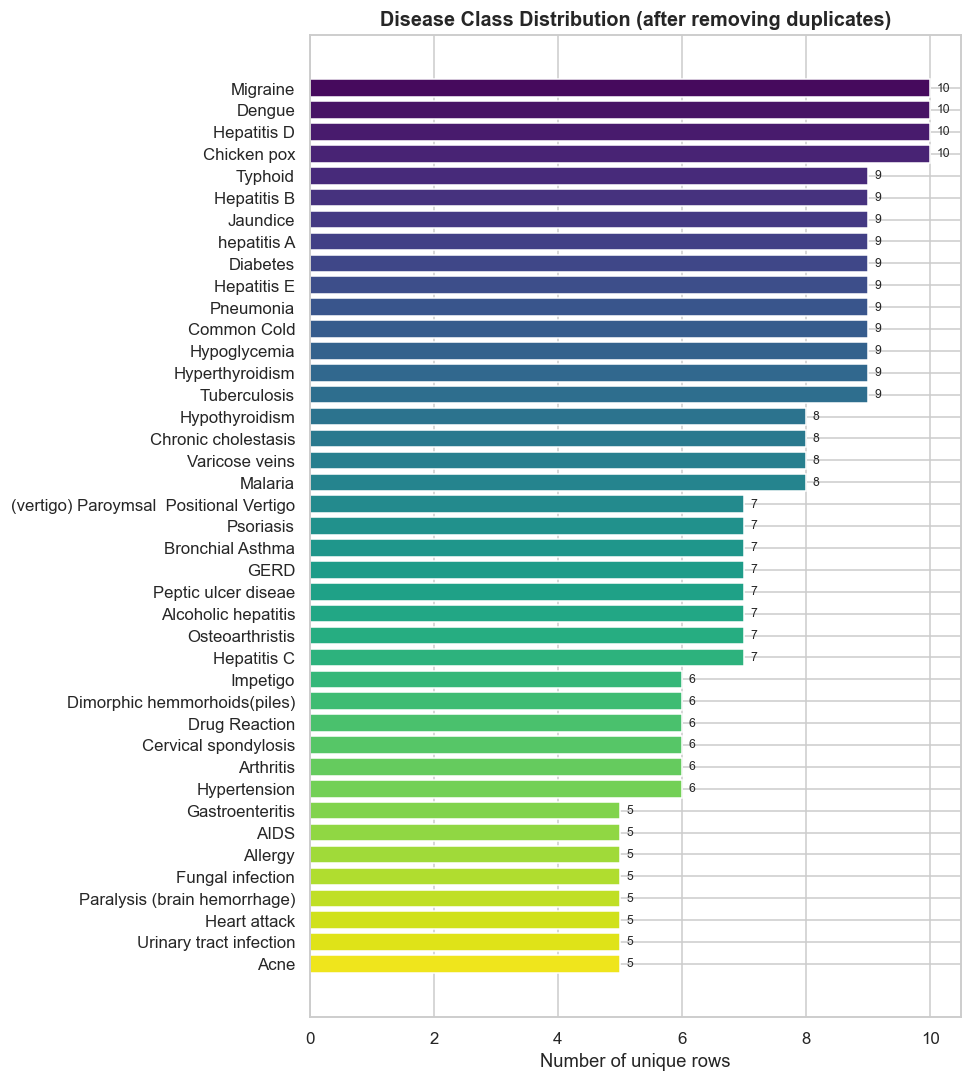

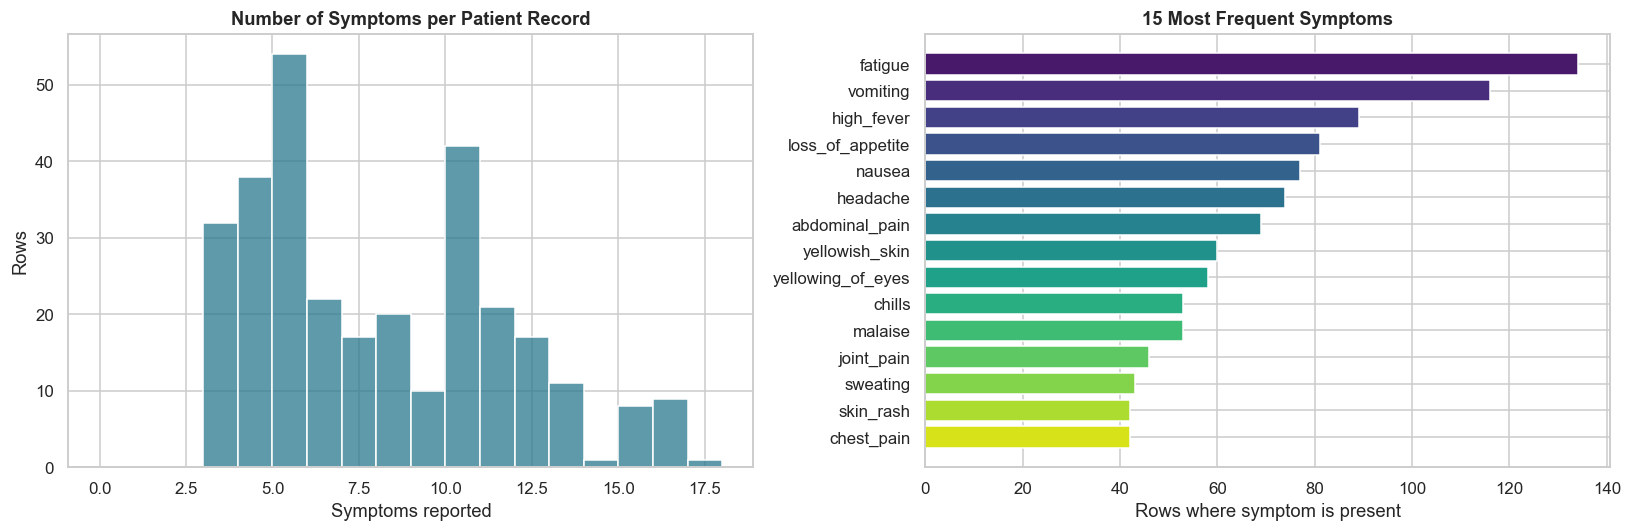

Avg symptoms per row : 7.6
Min / Max            : 3 / 17
Symptoms never used  : 1
Most common symptom  : fatigue (134 rows)


In [4]:
# ── EDA 1: Class distribution ───────────────────────────────────
counts = full["prognosis"].value_counts()

fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(counts.index, counts.values,
        color=sns.color_palette("viridis", len(counts)))
ax.invert_yaxis()
ax.set_xlabel("Number of unique rows")
ax.set_title("Disease Class Distribution (after removing duplicates)",
             fontsize=13, weight="bold")
for i, v in enumerate(counts.values):
    ax.text(v + 0.1, i, str(v), va="center", fontsize=8)
plt.tight_layout()
plt.show()

# ── EDA 2: Symptoms per row + most common symptoms ──────────────
symptoms_per_row = full[symptom_cols].sum(axis=1)
top_symptoms = full[symptom_cols].sum().sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(symptoms_per_row, bins=range(0, int(symptoms_per_row.max()) + 2),
             color="#2a788e", ax=axes[0])
axes[0].set_title("Number of Symptoms per Patient Record", weight="bold")
axes[0].set_xlabel("Symptoms reported")
axes[0].set_ylabel("Rows")

axes[1].barh(top_symptoms.index, top_symptoms.values,
             color=sns.color_palette("viridis", 15))
axes[1].invert_yaxis()
axes[1].set_title("15 Most Frequent Symptoms", weight="bold")
axes[1].set_xlabel("Rows where symptom is present")

plt.tight_layout()
plt.show()

# ── EDA 3: Key numbers ──────────────────────────────────────────
print(f"Avg symptoms per row : {symptoms_per_row.mean():.1f}")
print(f"Min / Max            : {symptoms_per_row.min()} / {symptoms_per_row.max()}")
print(f"Symptoms never used  : {(full[symptom_cols].sum() == 0).sum()}")
print(f"Most common symptom  : {top_symptoms.index[0]} ({top_symptoms.iloc[0]} rows)")

Training rows retained (including duplicates): 3918
Unique training patterns: 242
Unique-pattern holdout rows: 61
All 41 diseases represented in training: True


,Model,Accuracy,Precision,Recall,F1,F1 std
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000,0.0000
1,Random Forest,0.9985,0.9965,0.9965,0.9954,0.0080
2,Bernoulli NB,0.9914,0.9844,0.9848,0.9846,0.0267
3,Decision Tree,0.8598,0.7365,0.6968,0.6962,0.0287


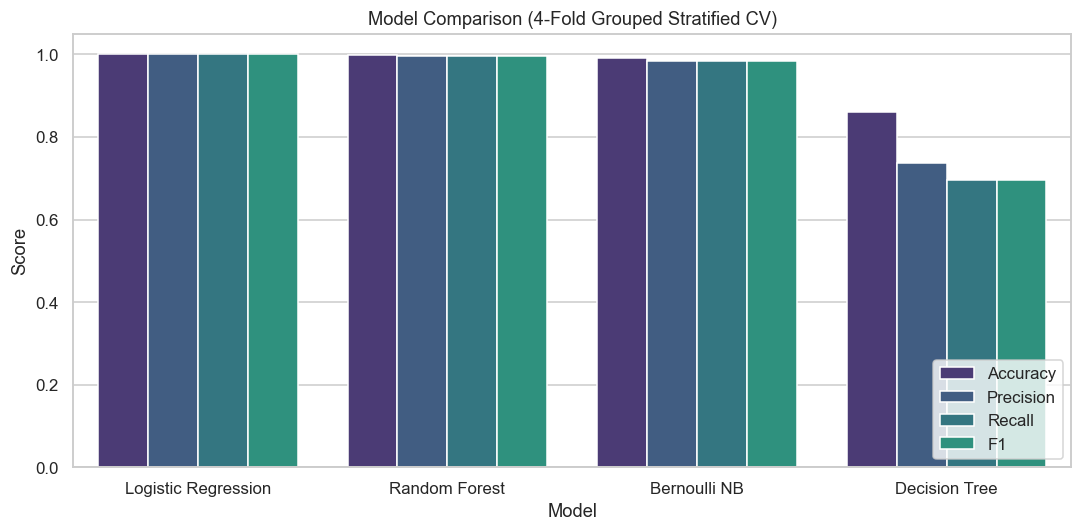

Selected model by grouped CV macro-F1: Logistic Regression


In [5]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB

# Split unique symptom patterns, not raw rows. This prevents identical patterns
# from appearing in both development training and holdout evaluation.
le = LabelEncoder()
y_unique = le.fit_transform(unique_patterns["prognosis"])
pattern_ids = unique_patterns["pattern_id"].to_numpy()

train_pattern_ids, holdout_pattern_ids = train_test_split(
    pattern_ids,
    test_size=0.2,
    stratify=y_unique,
    random_state=SEED
)

train_mask = train["pattern_id"].isin(set(train_pattern_ids))
holdout_mask = unique_patterns["pattern_id"].isin(set(holdout_pattern_ids))

# Retain all original duplicate rows for training patterns.
X_train = train.loc[train_mask, symptom_cols].to_numpy(dtype=np.uint8)
y_train = le.transform(train.loc[train_mask, "prognosis"])
groups_train = train.loc[train_mask, "pattern_id"].to_numpy()

# Evaluate once per unique held-out pattern, so repeated copies don't inflate the score.
holdout_df = unique_patterns.loc[holdout_mask].copy()
X_test = holdout_df[symptom_cols].to_numpy(dtype=np.uint8)
y_test = le.transform(holdout_df["prognosis"])

print(f"Training rows retained (including duplicates): {len(X_train)}")
print(f"Unique training patterns: {len(set(groups_train))}")
print(f"Unique-pattern holdout rows: {len(X_test)}")
print("All 41 diseases represented in training:",
      len(np.unique(y_train)) == len(le.classes_))

# Group-aware CV: every copy of a symptom pattern stays in the same fold.
train_unique_patterns = unique_patterns[
    unique_patterns["pattern_id"].isin(set(train_pattern_ids))
]
min_train_patterns_per_class = int(
    train_unique_patterns["prognosis"].value_counts().min()
)
n_splits = min(5, min_train_patterns_per_class)
if n_splits < 2:
    raise ValueError("Not enough training symptom patterns per disease for grouped cross-validation.")

cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Bernoulli NB": BernoulliNB(),
}
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

rows = []
for name, model in models.items():
    r = cross_validate(
        model, X_train, y_train,
        groups=groups_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    rows.append({
        "Model": name,
        "Accuracy": r["test_accuracy"].mean(),
        "Precision": r["test_precision_macro"].mean(),
        "Recall": r["test_recall_macro"].mean(),
        "F1": r["test_f1_macro"].mean(),
        "F1 std": r["test_f1_macro"].std(),
    })

results_df = pd.DataFrame(rows).sort_values(
    ["F1", "Accuracy"], ascending=False
).reset_index(drop=True)
display(results_df.round(4))

plot_df = results_df.melt(
    id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.title(f"Model Comparison ({n_splits}-Fold Grouped Stratified CV)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["Model"]
print("Selected model by grouped CV macro-F1:", best_name)

Selected model: Logistic Regression
Training accuracy (training rows include duplicates): 1.0
Unique-pattern holdout accuracy: 1.0

Classification report on held-out unique symptom patterns:
                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         1
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         

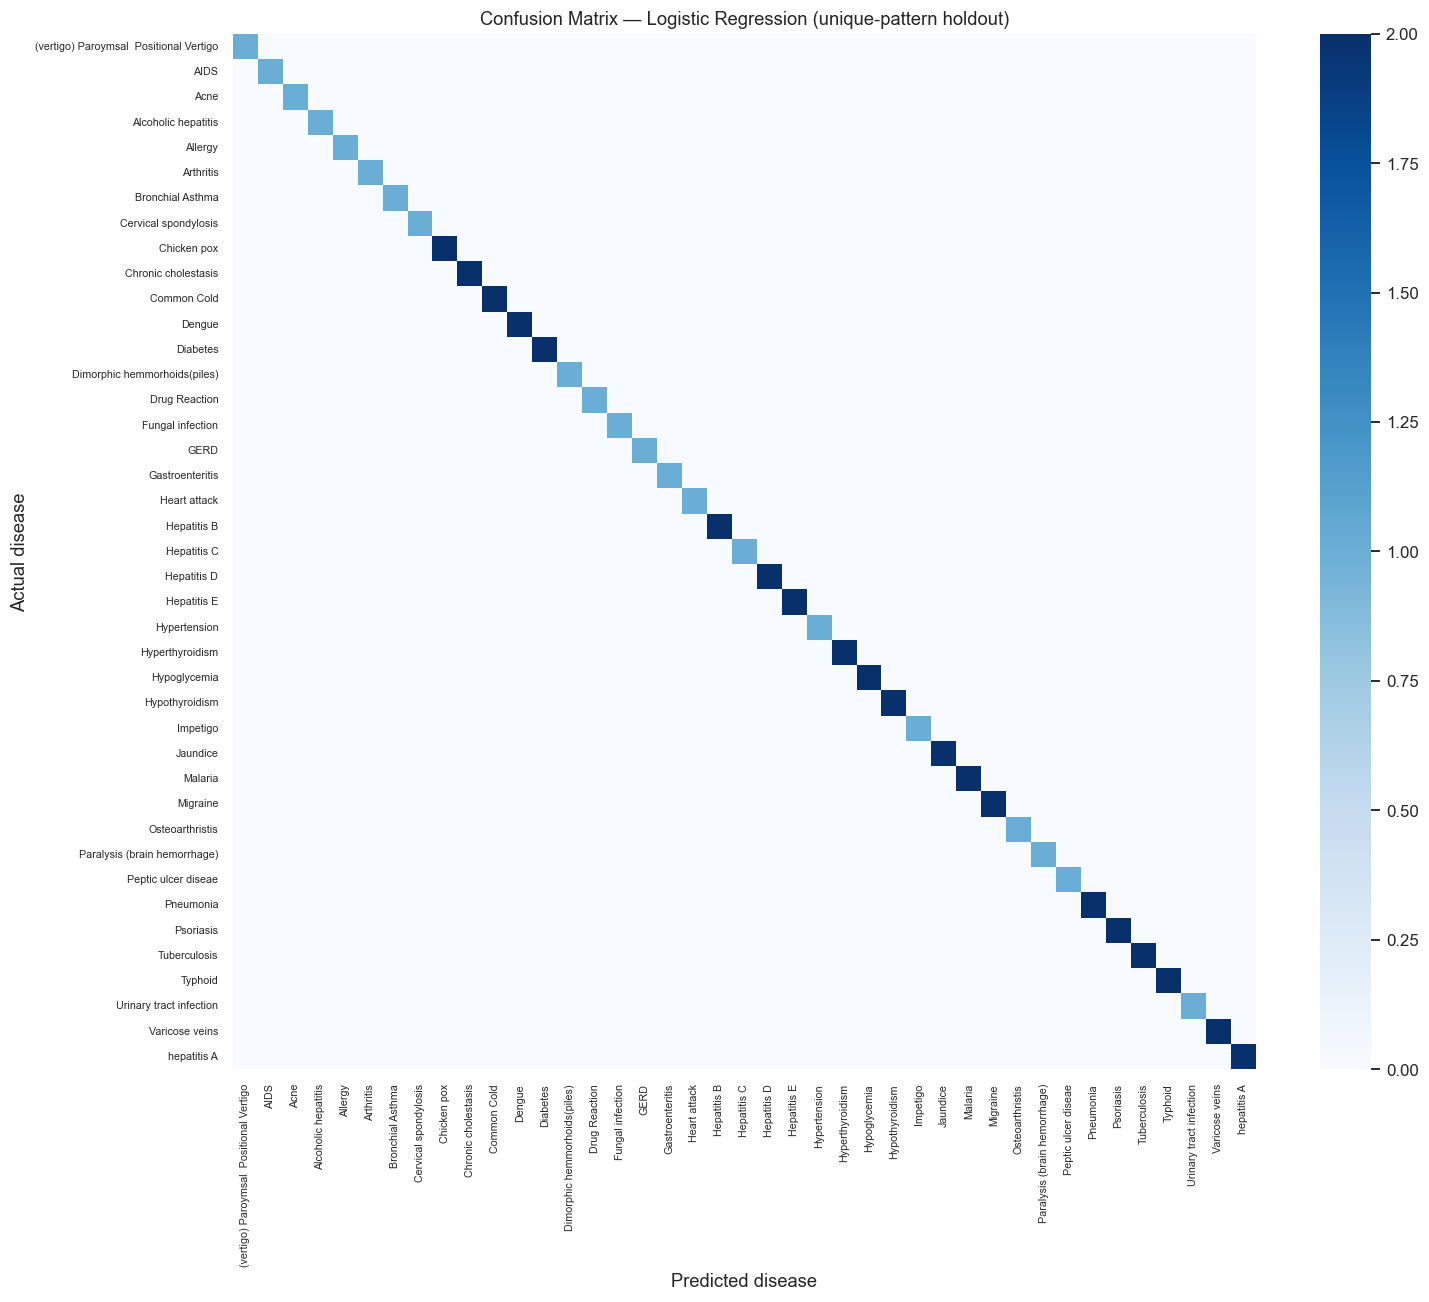

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

selected_model = models[best_name]
selected_model.fit(X_train, y_train)

y_pred = selected_model.predict(X_test)
holdout_accuracy = accuracy_score(y_test, y_pred)

print("Selected model:", best_name)
print("Training accuracy (training rows include duplicates):",
      round(selected_model.score(X_train, y_train), 4))
print("Unique-pattern holdout accuracy:", round(holdout_accuracy, 4))
print("\nClassification report on held-out unique symptom patterns:")
print(classification_report(
    y_test, y_pred, labels=np.arange(len(le.classes_)),
    target_names=le.classes_, zero_division=0
))

# Diagnostic only: a model trained on randomly shuffled labels should perform poorly.
shuffled_y = np.random.RandomState(SEED).permutation(y_train)
shuffle_model = type(selected_model)(**selected_model.get_params())
shuffle_model.fit(X_train, shuffled_y)
print("Shuffled-label holdout accuracy:",
      round(accuracy_score(y_test, shuffle_model.predict(X_test)), 4))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(le.classes_)))
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix — {best_name} (unique-pattern holdout)")
plt.xlabel("Predicted disease")
plt.ylabel("Actual disease")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

In [7]:
# Fit the selected model on the development training partition only.
# Do not fit on holdout patterns; those are reserved for evaluation.
best_model = models[best_name]
best_model.fit(X_train, y_train)
print(type(best_model).__name__, "trained on", len(X_train),
      "training rows from", len(set(groups_train)), "unique symptom patterns.")

LogisticRegression trained on 3918 training rows from 242 unique symptom patterns.


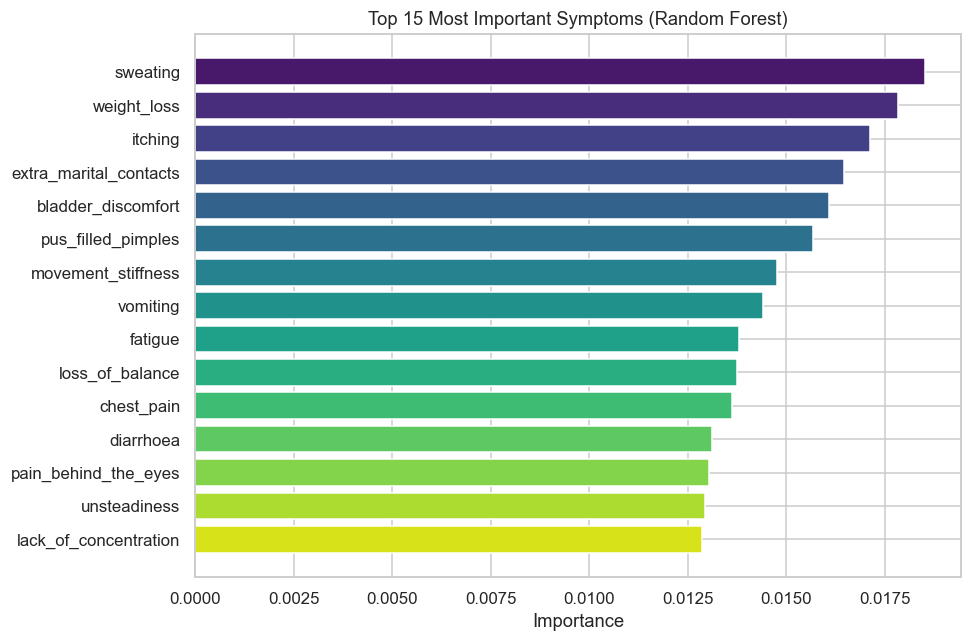

Saved bundle for: Logistic Regression
Sample output: [('Fungal infection', 91.3), ('Drug Reaction', 2.2), ('Acne', 0.8)]


In [8]:
import os
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Feature importance is model-specific. Use a Random Forest for the importance plot,
# regardless of which model wins the overall comparison.
importance_model = RandomForestClassifier(
    n_estimators=200, random_state=SEED, n_jobs=-1
)
importance_model.fit(X_train, y_train)
imp = pd.Series(importance_model.feature_importances_, index=symptom_cols)
top15 = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
plt.barh(top15.index, top15.values, color=sns.color_palette("viridis", 15))
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Top 15 Most Important Symptoms (Random Forest)")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=150)
plt.show()

bundle = {
    "model": best_model,
    "classes": list(le.classes_),
    "symptoms": symptom_cols,
    "selected_model": best_name,
    "evaluation_note": (
        "Educational symptom-pattern dataset; not clinically validated. "
        "Training retains duplicate rows, but identical symptom patterns are "
        "kept within one partition and holdout is evaluated once per unique pattern."
    ),
}
joblib.dump(bundle, "models/model_bundle.pkl")

results_df.to_csv("outputs/model_comparison.csv", index=False)
imp.sort_values(ascending=False).to_csv(
    "outputs/feature_importance.csv", header=["importance"]
)
full["prognosis"].value_counts().to_csv(
    "outputs/class_counts_unique_patterns.csv", header=["unique_patterns"]
)

loaded = joblib.load("models/model_bundle.pkl")

def predict(symptom_names):
    if not symptom_names:
        raise ValueError("Select at least one symptom.")
    unknown = sorted(set(symptom_names) - set(loaded["symptoms"]))
    if unknown:
        raise ValueError(f"Unknown symptoms: {unknown}")
    x = np.zeros((1, len(loaded["symptoms"])), dtype=np.uint8)
    for symptom in set(symptom_names):
        x[0, loaded["symptoms"].index(symptom)] = 1
    probabilities = loaded["model"].predict_proba(x)[0]
    top3 = np.argsort(probabilities)[::-1][:3]
    return [
        (loaded["classes"][i], round(float(probabilities[i]) * 100, 1))
        for i in top3
    ]

print("Saved bundle for:", loaded["selected_model"])
print("Sample output:", predict(["itching", "skin_rash", "nodal_skin_eruptions"]))